# AI / Data Job Salary Prediction

**ML Zoomcamp 2026 midterm project.** This notebook predicts indicative gross annual compensation in USD from job and geography attributes. It uses the project's shared preprocessing and model definitions in `model_utils.py`, and follows the same split, candidate models, validation selection, and final holdout evaluation as `train.py`.

The dataset is survey based and may have geographic and sample selection bias. Treat predictions as a statistical benchmark, not as an offer or an estimate of Georgia B2B market rates.


## 1. Setup and data download

Run from the `mlzc-26-salaryan` project directory. The download cell invokes the project's provenance-aware downloader and writes `data/source.json`. If the CSV is already present, the cell keeps it and loads it as is; run the downloader explicitly to refresh it.


In [1]:
from pathlib import Path
import json
import sys, os

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "src" / "mlzc_26_salaryan" / "model_utils.py").exists():
    candidate = PROJECT_DIR / "mlzc-26-salaryan"
    if (candidate / "src" / "mlzc_26_salaryan" / "model_utils.py").exists():
        PROJECT_DIR = candidate
    else:
        raise FileNotFoundError("Open this notebook from mlzc-26-salaryan or its parent directory.")

SRC_DIR = PROJECT_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
os.chdir(PROJECT_DIR)

DATA_PATH = PROJECT_DIR / "data" / "salaries.csv"
if not DATA_PATH.exists():
    from scripts.download import main as download_data
    download_data(DATA_PATH)

with (PROJECT_DIR / "data" / "source.json").open(encoding="utf-8") as f:
    source_info = json.load(f)
source_info


{'url': 'https://raw.githubusercontent.com/foorilla/ai-jobs-net-salaries/main/salaries.csv',
 'bytes': 8428290,
 'sha256': 'ceea75a58f85f2a8ecb805648b693c9fc541a80a6c3bf7121b53f9ecf6198f03'}

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from mlzc_26_salaryan.model_utils import FEATURES, REQUIRED, TARGET, clean_data, make_model
from mlzc_26_salaryan.train import metrics, split_data

raw = pd.read_csv(DATA_PATH)
print(f"Downloaded data: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())
from sklearn.inspection import permutation_importance


Downloaded data: 151,445 rows × 11 columns


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M


## 2. Data validation and cleaning

The shared `clean_data` function selects the required columns, coerces numeric target and year, removes missing or implausible targets, replaces missing feature values with `UNKNOWN`, trims categories, and drops exact duplicates. Salary amount/currency columns are deliberately excluded from model features to prevent target leakage.


In [3]:
print("Required input columns missing:", sorted(set(REQUIRED) - set(raw.columns)))
print("Missing values in raw data:")
display(raw.isna().sum().sort_values(ascending=False).rename("missing").to_frame())

df = clean_data(raw)
print(f"Rows after cleaning: {len(df):,} ({len(df) / len(raw):.1%} retained)")
print("Model features:", FEATURES)
print("Target:", TARGET)
display(df.head())
display(df[FEATURES + [TARGET, "work_year"]].describe(include="all").T)


Required input columns missing: []
Missing values in raw data:


,missing
work_year,0
experience_level,0
employment_type,0
job_title,0
salary,0
salary_currency,0
salary_in_usd,0
employee_residence,0
remote_ratio,0
company_location,0


Rows after cleaning: 71,890 (47.5% retained)
Model features: ['experience_level', 'employment_type', 'job_title', 'employee_residence', 'remote_ratio', 'company_location', 'company_size']
Target: salary_in_usd


,experience_level,employment_type,job_title,employee_residence,remote_ratio,company_location,company_size,salary_in_usd,work_year
0,EX,FT,Head of Data,US,0,US,M,348516,2025
1,EX,FT,Head of Data,US,0,US,M,232344,2025
2,SE,FT,Data Scientist,US,0,US,M,145400,2025
3,SE,FT,Data Scientist,US,0,US,M,81600,2025
4,MI,FT,Engineer,US,100,US,M,160000,2025


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
experience_level,71890,4,SE,37687,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,71890,4,FT,71140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_title,71890,422,Data Scientist,7156,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employee_residence,71890,104,US,60077,NaN,NaN,NaN,NaN,NaN,NaN,NaN
remote_ratio,71890,3,0,54061,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_location,71890,97,US,60139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_size,71890,3,M,70087,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary_in_usd,71890.0,NaN,NaN,NaN,151176.038531,77331.418295,15000.0,96003.0,138791.0,190400.0,800000.0
work_year,71890.0,NaN,NaN,NaN,2024.425177,0.721262,2020.0,2024.0,2025.0,2025.0,2025.0


## 3. Exploratory data analysis

Review target distribution and salary associations with key categorical variables. These summaries are descriptive and do not imply causal effects.


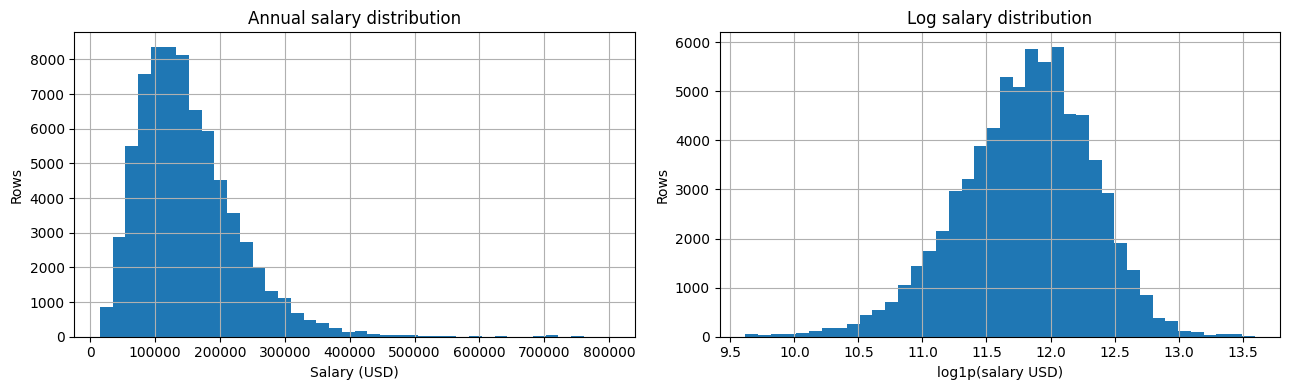

Median: $138,791; 10th–90th percentile: $67,500–$250,000


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df[TARGET].hist(bins=40, ax=axes[0])
axes[0].set(title="Annual salary distribution", xlabel="Salary (USD)", ylabel="Rows")
np.log1p(df[TARGET]).hist(bins=40, ax=axes[1])
axes[1].set(title="Log salary distribution", xlabel="log1p(salary USD)", ylabel="Rows")
plt.tight_layout()
plt.show()

print(f"Median: ${df[TARGET].median():,.0f}; 10th–90th percentile: ${df[TARGET].quantile(.1):,.0f}–${df[TARGET].quantile(.9):,.0f}")


/var/folders/hd/3ddrcgx14k37h3k3dj1psfc40000gn/T/ipykernel_11822/1129243140.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=order, showfliers=False)
/var/folders/hd/3ddrcgx14k37h3k3dj1psfc40000gn/T/ipykernel_11822/1129243140.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=order, showfliers=False)
/var/folders/hd/3ddrcgx14k37h3k3dj1psfc40000gn/T/ipykernel_11822/1129243140.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=order, showfliers=False)


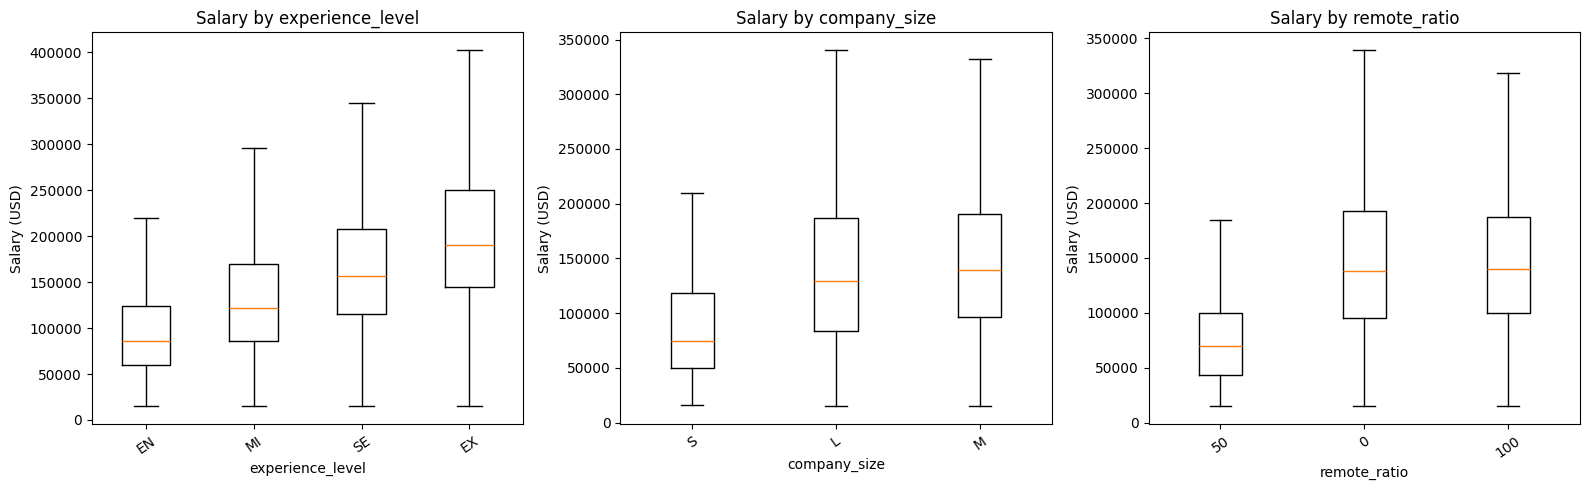

,rows,median,mean
experience_level,,,
EN,7970,85500.0,98041.0
MI,23392,122000.0,136263.0
SE,37687,156160.0,167832.0
EX,2841,190000.0,202080.0


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for column, ax, limit in zip(
    ["experience_level", "company_size", "remote_ratio"], axes, [None, None, None]
):
    order = df.groupby(column)[TARGET].median().sort_values().index
    groups = [df.loc[df[column] == value, TARGET].to_numpy() for value in order]
    ax.boxplot(groups, labels=order, showfliers=False)
    ax.set(title=f"Salary by {column}", xlabel=column, ylabel="Salary (USD)")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

summary = (df.groupby("experience_level")[TARGET]
           .agg(rows="size", median="median", mean="mean")
           .sort_values("median"))
display(summary.round({"median": 0, "mean": 0}))


## 4. Split data and establish a baseline

Use `train.split_data`, which prefers chronological train (through 2023), validation (2024), and test (2025+) when each partition has at least 20 rows. Otherwise it uses a documented deterministic random 60/20/20 fallback. All preprocessing is fitted inside each model pipeline on training data only.


In [6]:
MAX_ROWS = 50_000
model_df = df.sample(n=MAX_ROWS, random_state=42).reset_index(drop=True) if len(df) > MAX_ROWS else df.copy()
train_df, validation_df, test_df, split_description = split_data(model_df)
print(split_description)
display(pd.DataFrame({"rows": [len(train_df), len(validation_df), len(test_df)]}, index=["train", "validation", "test"]))


temporal: <=2023 / 2024 / >=2025


,rows
train,4122
validation,19338
test,26540


## 5. Compare models and tune hyperparameters

Compare a median dummy baseline, two Ridge regularization strengths, and two Random Forest depths using validation MAE and RMSE. Select by the lowest validation MAE, matching `train.py`. The test partition is not used for model selection.


In [7]:
candidates = [
    ("dummy_median", "dummy", 1),
    ("ridge_alpha_1", "ridge", 1),
    ("ridge_alpha_20", "ridge", 20),
    ("forest_depth_8", "forest", 8),
    ("forest_depth_12", "forest", 12),
]
validation_results = []
for name, kind, param in candidates:
    candidate_model = make_model(kind, param)
    candidate_model.fit(train_df[FEATURES], train_df[TARGET])
    validation_results.append({"candidate": name, "kind": kind, "param": param, **metrics(candidate_model, validation_df)})

comparison = pd.DataFrame(validation_results).sort_values("mae_usd").reset_index(drop=True)
display(comparison.round({"mae_usd": 0, "rmse_usd": 0}))
winner = min(validation_results, key=lambda row: row["mae_usd"])
print("Selected from validation:", winner)


,candidate,kind,param,mae_usd,rmse_usd
0,ridge_alpha_1,ridge,1,49934.0,71761.0
1,ridge_alpha_20,ridge,20,50024.0,71973.0
2,forest_depth_12,forest,12,50361.0,72058.0
3,forest_depth_8,forest,8,50429.0,72156.0
4,dummy_median,dummy,1,57526.0,78617.0


Selected from validation: {'candidate': 'ridge_alpha_1', 'kind': 'ridge', 'param': 1, 'mae_usd': 49934.15, 'rmse_usd': 71760.75}


## 6. Final model and held-out test evaluation

After choosing the candidate, refit it on the combined training and validation partitions. Evaluate once on the untouched test partition.


In [8]:
final_model = make_model(winner["kind"], winner["param"])
train_validation_df = pd.concat([train_df, validation_df], ignore_index=True)
final_model.fit(train_validation_df[FEATURES], train_validation_df[TARGET])
test_metrics = metrics(final_model, test_df)
print(f"Held-out test MAE: ${test_metrics['mae_usd']:,.0f}")
print(f"Held-out test RMSE: ${test_metrics['rmse_usd']:,.0f}")


Held-out test MAE: $47,218
Held-out test RMSE: $67,735


## 7. Feature importance

Permutation importance measures how much held-out MAE increases when one input column is shuffled. It is model-specific and descriptive; correlated inputs can split or hide importance, and the values do not show causal effects.

,feature,mae_increase_usd,std_usd
2,job_title,7463.0,254.0
0,experience_level,4733.0,438.0
3,employee_residence,3400.0,121.0
5,company_location,3072.0,177.0
1,employment_type,307.0,47.0
4,remote_ratio,67.0,9.0
6,company_size,-6.0,3.0


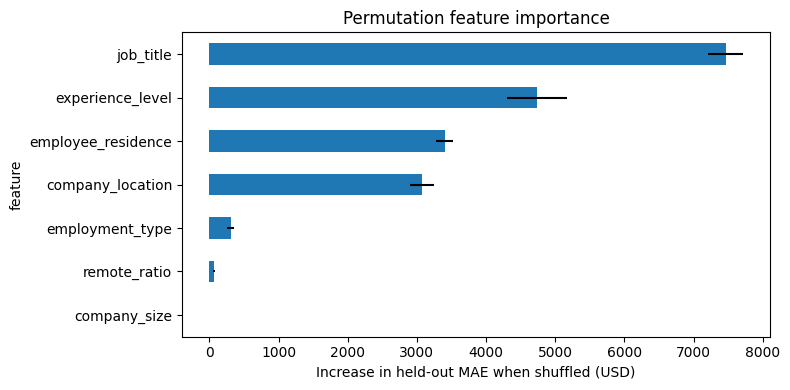

In [9]:
importance_data = test_df.sample(n=min(2_000, len(test_df)), random_state=42)
importance = permutation_importance(
    final_model, importance_data[FEATURES], importance_data[TARGET],
    scoring="neg_mean_absolute_error", n_repeats=2, random_state=42, n_jobs=1,
)
importance_results = pd.DataFrame({
    "feature": FEATURES,
    "mae_increase_usd": importance.importances_mean,
    "std_usd": importance.importances_std,
}).sort_values("mae_increase_usd", ascending=False)
display(importance_results.round(0))
ax = importance_results.sort_values("mae_increase_usd").plot.barh(
    x="feature", y="mae_increase_usd", xerr="std_usd", legend=False, figsize=(8, 4)
)
ax.set(xlabel="Increase in held-out MAE when shuffled (USD)", title="Permutation feature importance")
plt.tight_layout()
plt.show()


## 8. Conclusions and limitations

The validation comparison identifies the candidate with the lowest MAE, then the final model's generalization is summarized using the separate held-out test set. Compare the results with the median baseline: if the selected model provides little improvement, the available attributes may not support accurate individual salary estimates.

This is a historical survey dataset with possible sample selection, geographic, and year effects. Removing exact duplicate rows cannot detect repeated respondents. Model relationships are descriptive; salary is influenced by factors absent from these features. Results should not be used to set an offer or make an individual compensation decision.


In [10]:
baseline_mae = float(comparison.loc[comparison["candidate"] == "dummy_median", "mae_usd"].iloc[0])
mae_change = (baseline_mae - test_metrics["mae_usd"]) / baseline_mae * 100 if baseline_mae else 0
print(f"Selected candidate: {winner['candidate']}")
print(f"Validation MAE: ${winner['mae_usd']:,.0f}; dummy validation MAE: ${baseline_mae:,.0f}")
print(f"Test MAE relative to dummy validation MAE: {mae_change:.1f}% lower")
print("Test metrics (USD):", test_metrics)


Selected candidate: ridge_alpha_1
Validation MAE: $49,934; dummy validation MAE: $57,526
Test MAE relative to dummy validation MAE: 17.9% lower
Test metrics (USD): {'mae_usd': 47217.81, 'rmse_usd': 67735.4}
